<a href="https://colab.research.google.com/github/etoo-blip/Machine-Learning-Homework-6/blob/main/Homework6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework 6 — Fully Connected Neural Networks
## Name: Edwin Too
## ID: 801549588


In [ ]:

# Problem 1

from os import TFD_NONBLOCK
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

# Load the existing CSV file
df = pd.read_csv("Housing.csv")

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (545, 13)

First five rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

# Input features and target
X = df.drop(columns=["price"])
y = df["price"]

# 80% training, 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=100
)

# Convert categorical variables into numeric values
X_train = pd.get_dummies(X_train_raw, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test_raw, drop_first=True, dtype=int)

# Match feature columns between training and testing
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Input features after encoding:", X_train.shape[1])

Training samples: 436
Testing samples: 109
Input features after encoding: 13


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the original training data into training and validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

# Standardize input features
scaler_X = StandardScaler()

X_tr_scaled = scaler_X.fit_transform(X_tr)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

# Standardize target prices to help neural network training
scaler_y = StandardScaler()

y_tr_scaled = scaler_y.fit_transform(
    np.array(y_tr).reshape(-1, 1)
)

y_val_scaled = scaler_y.transform(
    np.array(y_val).reshape(-1, 1)
)

print("Training samples:", X_tr_scaled.shape)
print("Validation samples:", X_val_scaled.shape)
print("Testing samples:", X_test_scaled.shape)

Training samples: (348, 13)
Validation samples: (88, 13)
Testing samples: (109, 13)


In [5]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert training and validation data into tensors
X_tr_tensor = torch.tensor(X_tr_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

y_tr_tensor = torch.tensor(y_tr_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

# Create training DataLoader
train_dataset = TensorDataset(X_tr_tensor, y_tr_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Training input tensor:", X_tr_tensor.shape)
print("Training target tensor:", y_tr_tensor.shape)
print("Number of training batches:", len(train_loader))

Training input tensor: torch.Size([348, 13])
Training target tensor: torch.Size([348, 1])
Number of training batches: 11


In [6]:
import torch.nn as nn

torch.manual_seed(42)

class HousingFCNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


model = HousingFCNN(input_size=X_tr_scaled.shape[1])

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

HousingFCNN(
  (network): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [7]:
import copy

epochs = 500
patience = 40

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    train_loss = running_loss / len(train_dataset)

    # Validation
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val_tensor)
        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save best model
    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

# Restore best weights
model.load_state_dict(best_model_state)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch  50 | Train Loss: 0.1201 | Val Loss: 0.3506

Early stopping at epoch 90

Best epoch: 50
Best validation loss: 0.3506


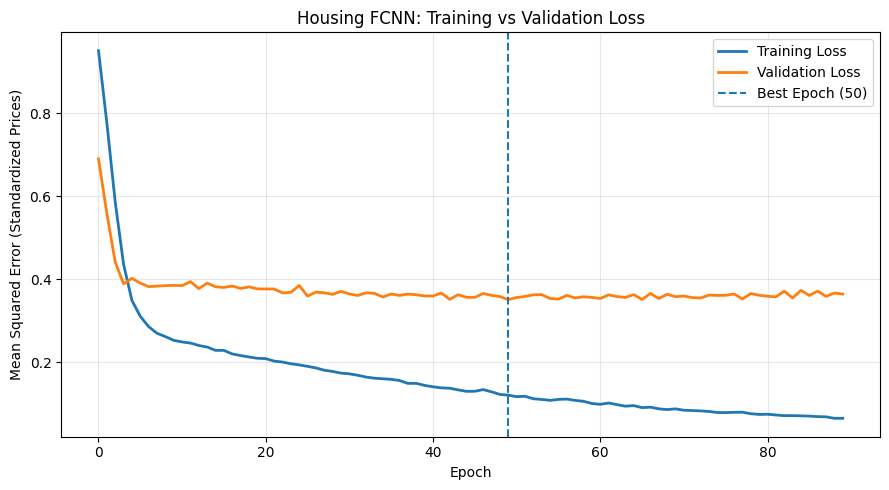

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Standardized Prices)")
plt.title("Housing FCNN: Training vs Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Convert test inputs to PyTorch tensor
X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

# Generate predictions using the best trained model
model.eval()

with torch.no_grad():
    y_pred_scaled = model(X_test_tensor).numpy()

# Convert predicted prices back to original units
y_pred = scaler_y.inverse_transform(
    y_pred_scaled
).ravel()

# Actual test prices
y_actual = np.asarray(y_test)

# Calculate evaluation metrics
fcnn_mse = mean_squared_error(y_actual, y_pred)
fcnn_rmse = np.sqrt(fcnn_mse)
fcnn_r2 = r2_score(y_actual, y_pred)

print("FCNN TEST PERFORMANCE")
print("-----------------------------")
print(f"MSE  : {fcnn_mse:,.2f}")
print(f"RMSE : {fcnn_rmse:,.2f}")
print(f"R²   : {fcnn_r2:.4f}")

FCNN TEST PERFORMANCE
-----------------------------
MSE  : 1,159,289,765,888.00
RMSE : 1,076,703.19
R²   : 0.6715


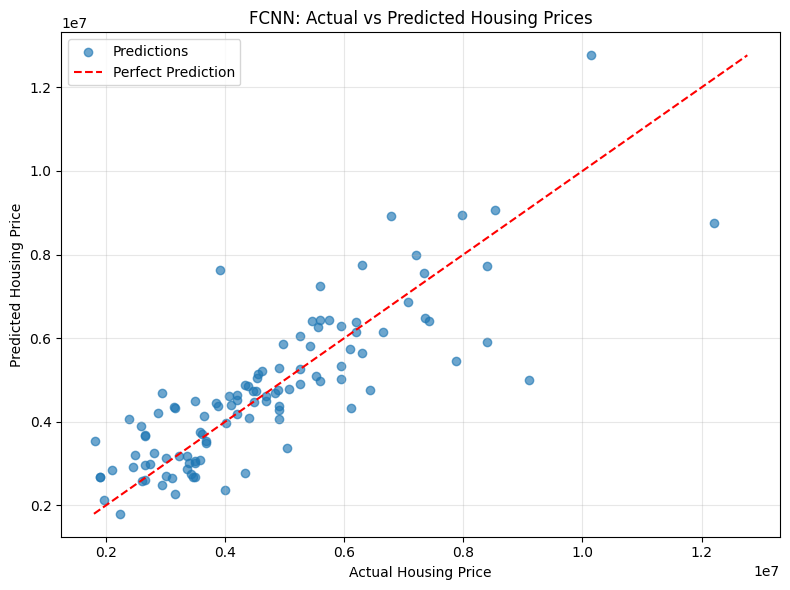

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_actual,
    y_pred,
    alpha=0.65,
    label="Predictions"
)

min_price = min(y_actual.min(), y_pred.min())
max_price = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Housing Price")
plt.ylabel("Predicted Housing Price")
plt.title("FCNN: Actual vs Predicted Housing Prices")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_tr_scaled, y_tr)

lr_pred = lr_model.predict(X_test_scaled)

# Support Vector Regression
# Scale the target for SVR to make optimization easier
svr_model = SVR(kernel="rbf", C=10, epsilon=0.1)

svr_model.fit(
    X_tr_scaled,
    y_tr_scaled.ravel()
)

svr_pred_scaled = svr_model.predict(
    X_test_scaled
).reshape(-1, 1)

svr_pred = scaler_y.inverse_transform(
    svr_pred_scaled
).ravel()

# Function to calculate regression metrics
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return [mse, rmse, r2]

# Comparison table
results = pd.DataFrame(
    {
        "Linear Regression": regression_metrics(y_actual, lr_pred),
        "SVR": regression_metrics(y_actual, svr_pred),
        "FCNN": regression_metrics(y_actual, y_pred)
    },
    index=["MSE", "RMSE", "R²"]
).T

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))

MODEL PERFORMANCE COMPARISON


,MSE,RMSE,R²
Linear Regression,1.131048e+12,1.063507e+06,0.6795
SVR,1.317256e+12,1.147718e+06,0.6268
FCNN,1.159290e+12,1.076703e+06,0.6715


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Load breast cancer dataset
cancer_df = pd.read_csv("Cancer.csv")

# Remove unnecessary columns
cancer_df = cancer_df.drop(
    columns=["id", "Unnamed: 32"]
)

# Encode diagnosis
cancer_df["diagnosis"] = cancer_df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Dataset shape:", cancer_df.shape)

print("\nClass distribution:")
print(cancer_df["diagnosis"].value_counts())

print("\nMissing values:")
print(cancer_df.isnull().sum().sum())

display(cancer_df.head())

Dataset shape: (569, 31)

Class distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64

Missing values:
0


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X_cancer = cancer_df.drop(columns=["diagnosis"])
y_cancer = cancer_df["diagnosis"]

# 80% training and 20% testing
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.20,
    random_state=42,
    stratify=y_cancer
)

# Split training data into training and validation
X_tr_c, X_val_c, y_tr_c, y_val_c = train_test_split(
    X_train_c,
    y_train_c,
    test_size=0.20,
    random_state=42,
    stratify=y_train_c
)

# Standardize features using training subset only
scaler_c = StandardScaler()

X_tr_c_scaled = scaler_c.fit_transform(X_tr_c)
X_val_c_scaled = scaler_c.transform(X_val_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

print("Training:", X_tr_c_scaled.shape)
print("Validation:", X_val_c_scaled.shape)
print("Testing:", X_test_c_scaled.shape)

Training: (364, 30)
Validation: (91, 30)
Testing: (114, 30)


In [15]:
from torch.utils.data import TensorDataset, DataLoader

X_tr_c_tensor = torch.tensor(
    X_tr_c_scaled, dtype=torch.float32
)
X_val_c_tensor = torch.tensor(
    X_val_c_scaled, dtype=torch.float32
)

y_tr_c_tensor = torch.tensor(
    y_tr_c.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)
y_val_c_tensor = torch.tensor(
    y_val_c.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

train_dataset_c = TensorDataset(
    X_tr_c_tensor,
    y_tr_c_tensor
)

train_loader_c = DataLoader(
    train_dataset_c,
    batch_size=32,
    shuffle=True
)

print("Input tensor:", X_tr_c_tensor.shape)
print("Target tensor:", y_tr_c_tensor.shape)
print("Training batches:", len(train_loader_c))

Input tensor: torch.Size([364, 30])
Target tensor: torch.Size([364, 1])
Training batches: 12


In [16]:
import torch
import torch.nn as nn

torch.manual_seed(42)

class CancerFCNN(nn.Module):
    def __init__(self, input_size=30):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


cancer_model = CancerFCNN(input_size=30)

# Binary classification loss
cancer_criterion = nn.BCEWithLogitsLoss()

# Adam optimizer
cancer_optimizer = torch.optim.Adam(
    cancer_model.parameters(),
    lr=0.001
)

print(cancer_model)

CancerFCNN(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [17]:
import copy
import numpy as np

max_epochs = 300
patience = 30

cancer_train_losses = []
cancer_val_losses = []
cancer_train_accuracies = []
cancer_val_accuracies = []

best_val_loss = float("inf")
best_cancer_state = None
best_epoch_cancer = 0
epochs_no_improvement = 0

for epoch in range(max_epochs):

    # Training
    cancer_model.train()

    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for X_batch, y_batch in train_loader_c:

        cancer_optimizer.zero_grad()

        logits = cancer_model(X_batch)
        loss = cancer_criterion(logits, y_batch)

        loss.backward()
        cancer_optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

        correct_train += (predictions == y_batch).sum().item()
        total_train += y_batch.size(0)

    train_loss = running_loss / total_train
    train_accuracy = correct_train / total_train

    # Validation
    cancer_model.eval()

    with torch.no_grad():
        val_logits = cancer_model(X_val_c_tensor)

        val_loss = cancer_criterion(
            val_logits,
            y_val_c_tensor
        ).item()

        val_probabilities = torch.sigmoid(val_logits)
        val_predictions = (val_probabilities >= 0.5).float()

        val_accuracy = (
            (val_predictions == y_val_c_tensor)
            .float()
            .mean()
            .item()
        )

    cancer_train_losses.append(train_loss)
    cancer_val_losses.append(val_loss)

    cancer_train_accuracies.append(train_accuracy)
    cancer_val_accuracies.append(val_accuracy)

    # Save model with lowest validation loss
    if val_loss < best_val_loss - 1e-6:

        best_val_loss = val_loss
        best_epoch_cancer = epoch + 1

        best_cancer_state = copy.deepcopy(
            cancer_model.state_dict()
        )

        epochs_no_improvement = 0

    else:
        epochs_no_improvement += 1

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

    if epochs_no_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

# Restore best model weights
cancer_model.load_state_dict(best_cancer_state)

print(f"\nBest epoch: {best_epoch_cancer}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch  20 | Train Loss: 0.0569 | Val Loss: 0.0769 | Train Acc: 0.9863 | Val Acc: 0.9780
Epoch  40 | Train Loss: 0.0310 | Val Loss: 0.0726 | Train Acc: 0.9945 | Val Acc: 0.9780
Epoch  60 | Train Loss: 0.0176 | Val Loss: 0.0725 | Train Acc: 0.9945 | Val Acc: 0.9780

Early stopping at epoch 75

Best epoch: 45
Best validation loss: 0.0723


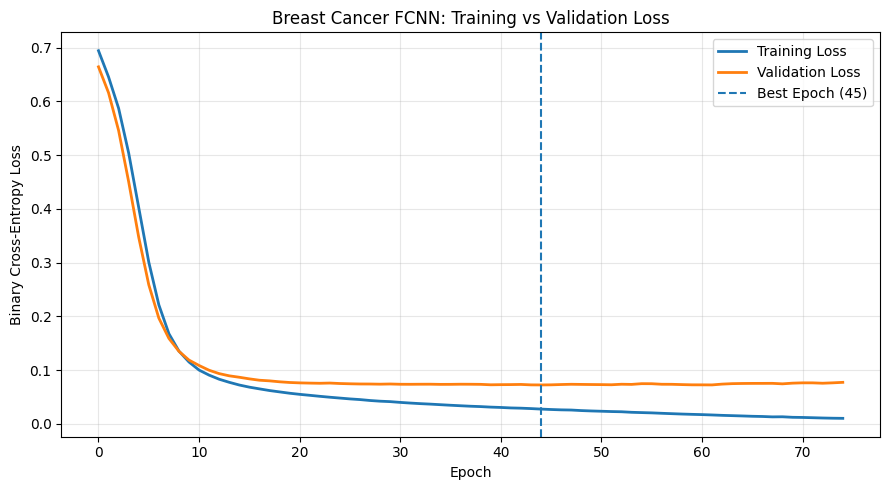

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    cancer_train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    cancer_val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.axvline(
    best_epoch_cancer - 1,
    linestyle="--",
    label=f"Best Epoch ({best_epoch_cancer})"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Breast Cancer FCNN: Training vs Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

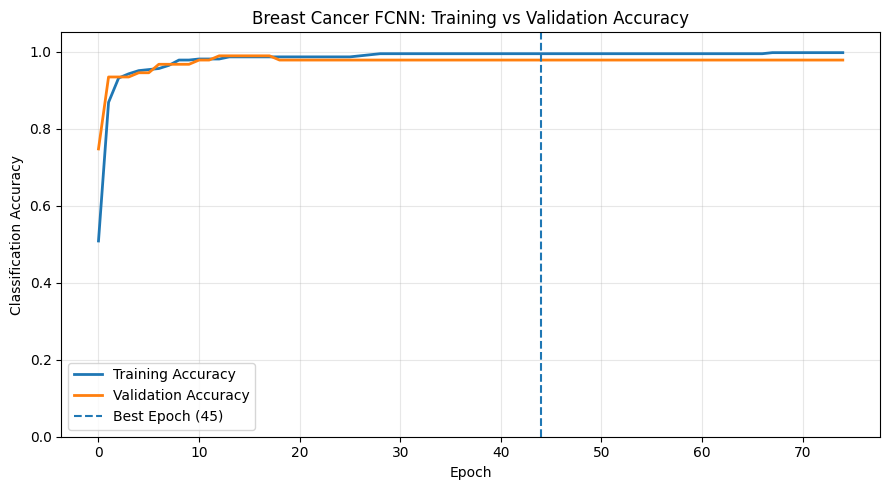

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(
    cancer_train_accuracies,
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    cancer_val_accuracies,
    label="Validation Accuracy",
    linewidth=2
)

plt.axvline(
    best_epoch_cancer - 1,
    linestyle="--",
    label=f"Best Epoch ({best_epoch_cancer})"
)

plt.xlabel("Epoch")
plt.ylabel("Classification Accuracy")
plt.title("Breast Cancer FCNN: Training vs Validation Accuracy")

plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import numpy as np
import torch

# Convert test features to PyTorch tensors
X_test_c_tensor = torch.tensor(
    X_test_c_scaled,
    dtype=torch.float32
)

# Use the best model saved during training
cancer_model.eval()

with torch.no_grad():
    test_logits = cancer_model(X_test_c_tensor)

    # Convert logits to probabilities
    test_probabilities = torch.sigmoid(test_logits)

    # Convert probabilities to class predictions
    y_pred_cancer = (
        test_probabilities >= 0.5
    ).int().numpy().ravel()

# Actual test labels
y_actual_cancer = y_test_c.to_numpy()

# Calculate classification metrics
fcnn_accuracy = accuracy_score(
    y_actual_cancer, y_pred_cancer
)

fcnn_precision = precision_score(
    y_actual_cancer, y_pred_cancer,
    zero_division=0
)

fcnn_recall = recall_score(
    y_actual_cancer, y_pred_cancer,
    zero_division=0
)

fcnn_f1 = f1_score(
    y_actual_cancer, y_pred_cancer,
    zero_division=0
)

print("FCNN TEST PERFORMANCE")
print("------------------------------")
print(f"Accuracy : {fcnn_accuracy:.4f}")
print(f"Precision: {fcnn_precision:.4f}")
print(f"Recall   : {fcnn_recall:.4f}")
print(f"F1 Score : {fcnn_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_actual_cancer,
        y_pred_cancer,
        target_names=["Benign", "Malignant"]
    )
)

FCNN TEST PERFORMANCE
------------------------------
Accuracy : 0.9825
Precision: 1.0000
Recall   : 0.9524
F1 Score : 0.9756

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



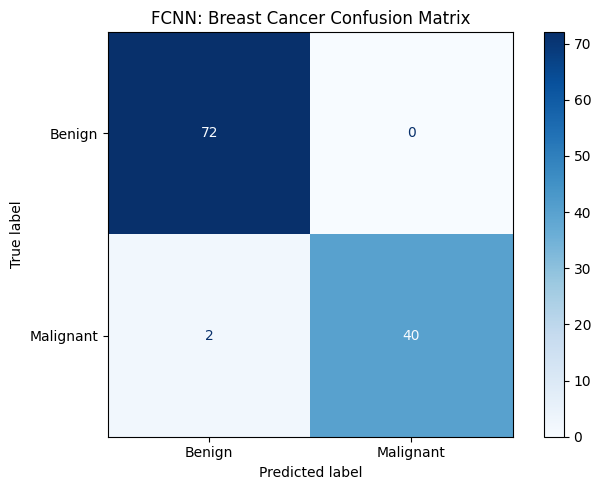

True Negatives : 72
False Positives: 0
False Negatives: 2
True Positives : 40


In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_actual_cancer,
    y_pred_cancer,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("FCNN: Breast Cancer Confusion Matrix")
plt.tight_layout()
plt.show()

print("True Negatives :", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives :", cm[1, 1])

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# 1. Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_tr_c_scaled,
    y_tr_c
)

logistic_pred = logistic_model.predict(
    X_test_c_scaled
)

# 2. Support Vector Machine
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

svm_model.fit(
    X_tr_c_scaled,
    y_tr_c
)

svm_pred = svm_model.predict(
    X_test_c_scaled
)

# Function to calculate classification metrics
def classification_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

# Compare all three models
comparison = pd.DataFrame({
    "Logistic Regression": classification_metrics(
        y_actual_cancer, logistic_pred
    ),
    "SVM": classification_metrics(
        y_actual_cancer, svm_pred
    ),
    "FCNN": classification_metrics(
        y_actual_cancer, y_pred_cancer
    )
}).T

print("BREAST CANCER MODEL COMPARISON")
display(comparison.round(4))

BREAST CANCER MODEL COMPARISON


,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.9825,0.9762,0.9762,0.9762
SVM,0.9737,0.9756,0.9524,0.9639
FCNN,0.9825,1.0000,0.9524,0.9756


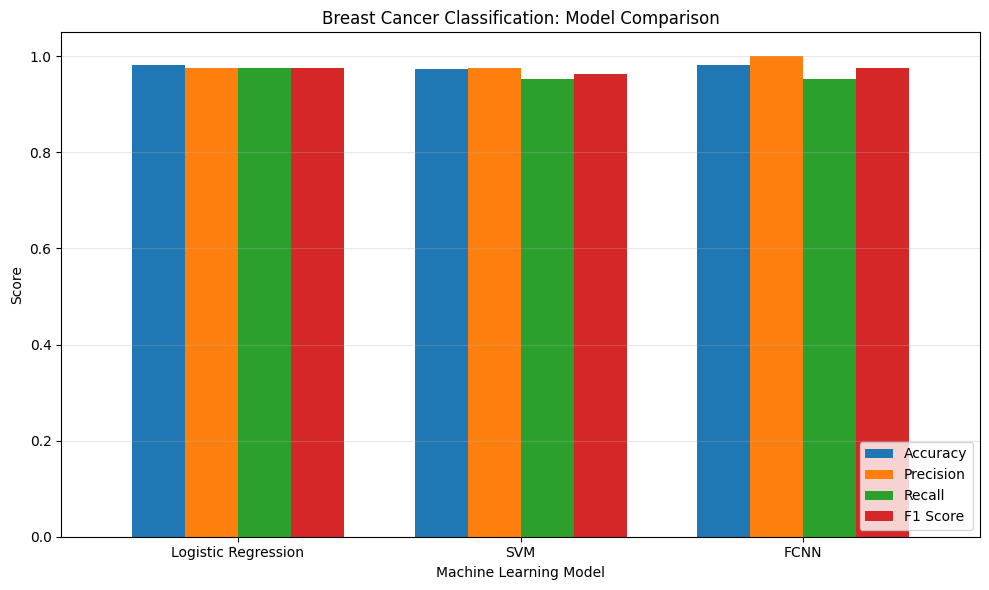

In [23]:
ax = comparison.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Breast Cancer Classification: Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()